<a href="https://colab.research.google.com/github/HemanthSagarSR/BIS_LAB/blob/main/WEEK_1_PSO_1BM24CS116.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SAMPLE INPUT
Tasks: ['T1', 'T2', 'T3', 'T4', 'T5']
Number of VMs: 1
Execution times: [4, 6, 5, 3, 7]
Energy rate: 2
Cost rate: 1
Weights: 0.3333333333333333 0.3333333333333333 0.3333333333333333

SCHEDULED OUTPUT
VM1: T2 -> T4 -> T3 -> T1 -> T5
Total execution time: 25
Total energy consumption: 50
Total resource cost: 25
Fitness value: 1.0


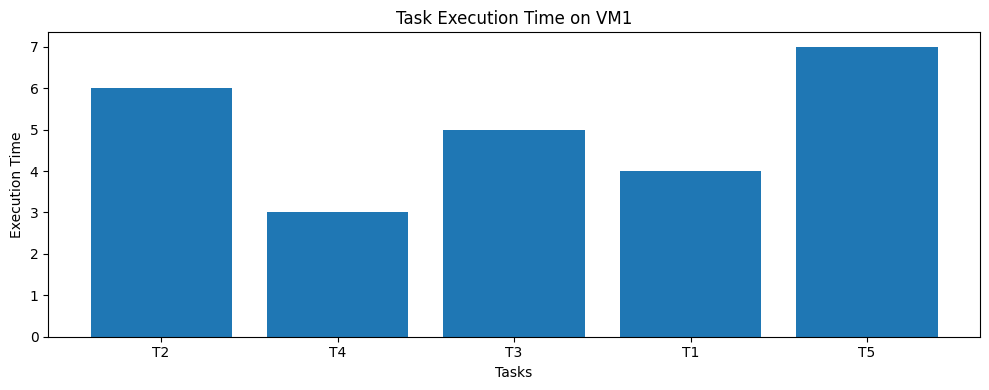

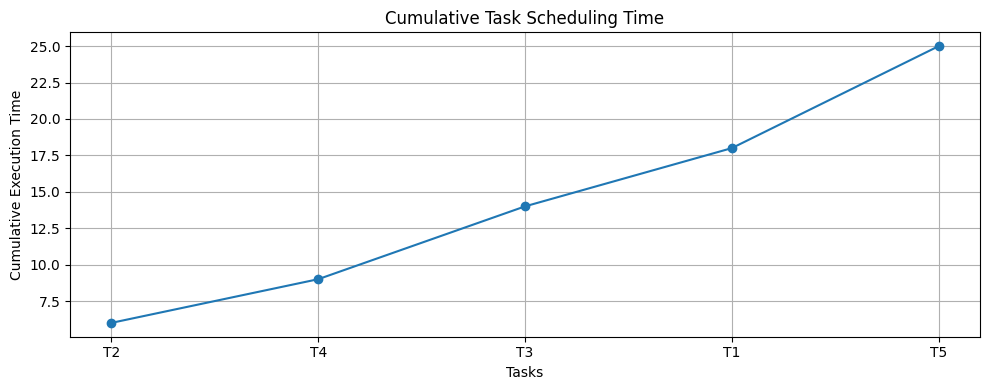

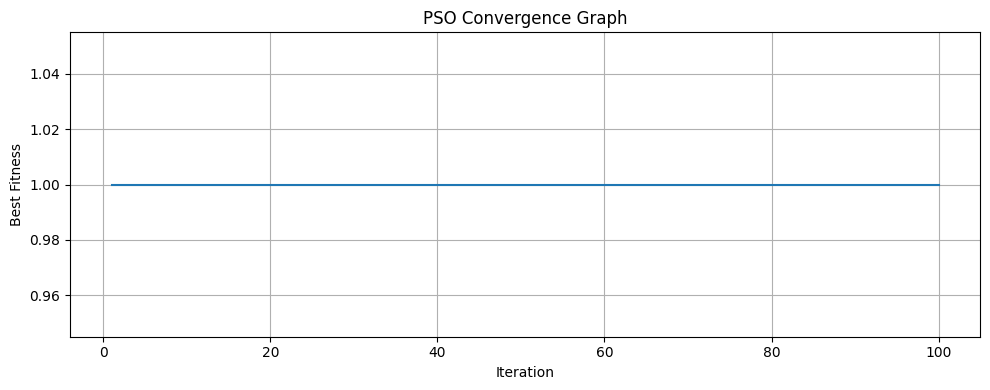

In [2]:
import random
import matplotlib.pyplot as plt

random.seed(42)

tasks = ["T1", "T2", "T3", "T4", "T5"]
execution_time = [4, 6, 5, 3, 7]
energy_rate = 2
cost_rate = 1
alpha = beta = gamma = 1 / 3
num_particles = 20
iterations = 100
n = len(tasks)

def evaluate(position):
    sequence = sorted(range(n), key=lambda i: position[i])
    time = sum(execution_time[i] for i in sequence)
    energy = time * energy_rate
    cost = time * cost_rate
    fitness = alpha * time / 25 + beta * energy / 50 + gamma * cost / 25
    return fitness, sequence, time, energy, cost

particles = [[random.random() for _ in range(n)] for _ in range(num_particles)]
velocities = [[random.uniform(-1, 1) for _ in range(n)] for _ in range(num_particles)]
pbest = [p[:] for p in particles]
pbest_scores = [evaluate(p)[0] for p in particles]
gbest = pbest[pbest_scores.index(min(pbest_scores))][:]
gbest_score = min(pbest_scores)
history = []

for _ in range(iterations):
    for i in range(num_particles):
        for j in range(n):
            velocities[i][j] = (
                0.5 * velocities[i][j]
                + 1.5 * random.random() * (pbest[i][j] - particles[i][j])
                + 1.5 * random.random() * (gbest[j] - particles[i][j])
            )
            particles[i][j] += velocities[i][j]

        score = evaluate(particles[i])[0]

        if score < pbest_scores[i]:
            pbest[i] = particles[i][:]
            pbest_scores[i] = score

            if score < gbest_score:
                gbest = particles[i][:]
                gbest_score = score

    history.append(gbest_score)

fitness, sequence, total_time, energy, cost = evaluate(gbest)

print("SAMPLE INPUT")
print("Tasks:", tasks)
print("Number of VMs: 1")
print("Execution times:", execution_time)
print("Energy rate:", energy_rate)
print("Cost rate:", cost_rate)
print("Weights:", alpha, beta, gamma)

print("\nSCHEDULED OUTPUT")
print("VM1:", " -> ".join(tasks[i] for i in sequence))
print("Total execution time:", total_time)
print("Total energy consumption:", energy)
print("Total resource cost:", cost)
print("Fitness value:", round(fitness, 4))

scheduled_tasks = [tasks[i] for i in sequence]
scheduled_times = [execution_time[i] for i in sequence]
cumulative_times = []
current_time = 0

for duration in scheduled_times:
    current_time += duration
    cumulative_times.append(current_time)

plt.figure(figsize=(10, 4))
plt.bar(scheduled_tasks, scheduled_times)
plt.xlabel("Tasks")
plt.ylabel("Execution Time")
plt.title("Task Execution Time on VM1")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(scheduled_tasks, cumulative_times, marker="o")
plt.xlabel("Tasks")
plt.ylabel("Cumulative Execution Time")
plt.title("Cumulative Task Scheduling Time")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(range(1, iterations + 1), history)
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("PSO Convergence Graph")
plt.grid(True)
plt.tight_layout()
plt.show()